In [1]:
try:
    import google.colab
    print('Running on CoLab')
    #!pip install roboticstoolbox-python>=1.0.2
    !pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    !pip install spatialmath-python>=1.1.5
    !pip install bdsim
    !pip install --no-deps rvc3python
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

In [2]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *

### Braitenberg Vehicles

In [3]:
def sensorfield(x, y):
    xc, yc = (60, 90)
    return 200 / ((x - xc) ** 2 + (y - yc) ** 2 + 200)

┌───────────────┬────┬────┬─────────────┬────────┬─────────────┬───────────────────┐
│     block     │ nc │ nd │    type     │ inport │   source    │    source type    │
├───────────────┼────┼────┼─────────────┼────────┼─────────────┼───────────────────┤
│ Ks            │ 0  │ 0  │ gain        │ 0      │ sum.1       │ float64           │
├───────────────┼────┼────┼─────────────┼────────┼─────────────┼───────────────────┤
│ Kv            │ 0  │ 0  │ gain        │ 0      │ sum.0       │ float64           │
├───────────────┼────┼────┼─────────────┼────────┼─────────────┼───────────────────┤
│ leftsensor    │ 0  │ 0  │ function    │ 0      │ vehicle     │ ndarray(3,).int64 │
├───────────────┼────┼────┼─────────────┼────────┼─────────────┼───────────────────┤
│ rightsensor   │ 0  │ 0  │ function    │ 0      │ vehicle     │ ndarray(3,).int64 │
├───────────────┼────┼────┼─────────────┼────────┼─────────────┼───────────────────┤
│ sensor field  │ 0  │ 0  │ vehicleplot │ 0      │ vehicle     │ 

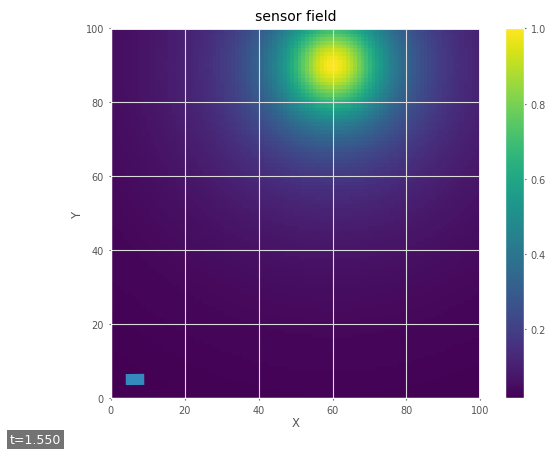

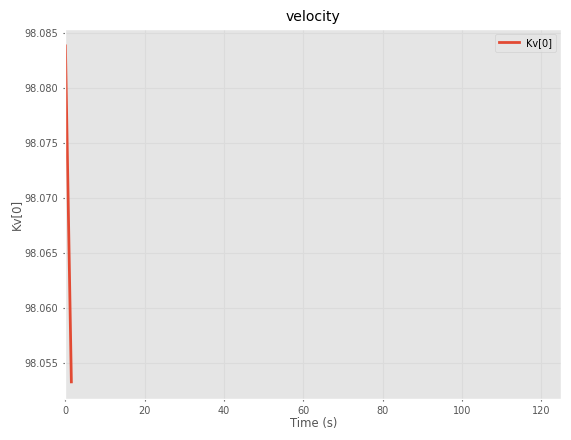

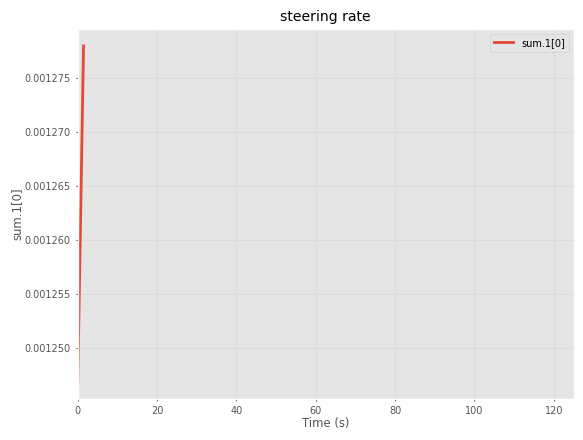

KeyboardInterrupt: 

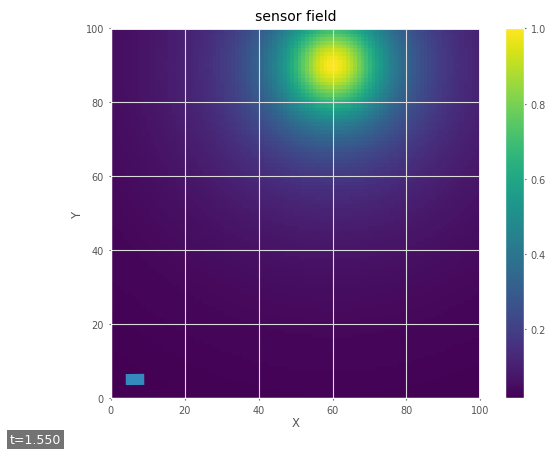

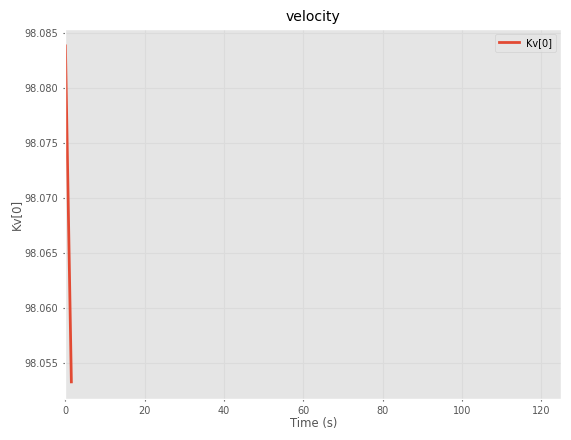

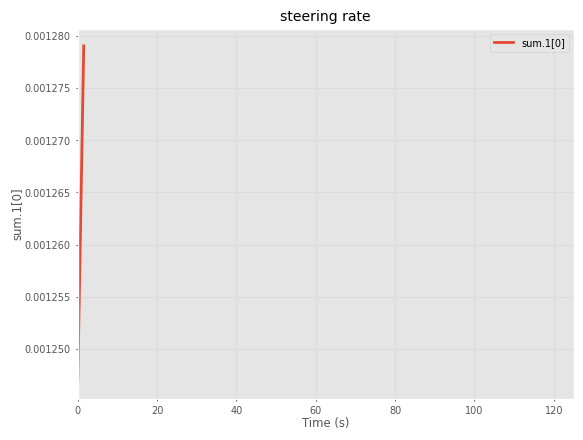

In [11]:
%run -i "models_dir/braitenberg.py"

### Simple Automata

In [3]:
house = rtb_load_matfile("data/house.mat")

{'__header__': b'MATLAB 5.0 MAT-file, Platform: MACI64, Created on: Thu Jul 15 16:26:17 2021',
 '__version__': '1.0',
 '__globals__': [],
 'floorplan': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(397, 596), dtype=uint8),
 'places': {'kitchen': array([320, 190], dtype=uint16),
  'garage': array([500, 150], dtype=uint16),
  'br1': array([ 50, 220], dtype=uint8),
  'br2': array([120,  50], dtype=uint8),
  'br3': array([50, 50], dtype=uint8),
  'nook': array([320, 280], dtype=uint16),
  'mudroom': array([320,  50], dtype=uint16),
  'patio': array([200, 350], dtype=uint16),
  'study': array([220,  50], dtype=uint8),
  'garden': array([100, 350], dtype=uint16),
  'driveway': array([500, 350], dtype=uint16),
  'living': array([220, 200], dtype=uint8)}}

In [4]:
floorplan = house["floorplan"]
floorplan.shape

(397, 596)

In [5]:
places = house["places"]
places.keys()

dict_keys(['kitchen', 'garage', 'br1', 'br2', 'br3', 'nook', 'mudroom', 'patio', 'study', 'garden', 'driveway', 'living'])

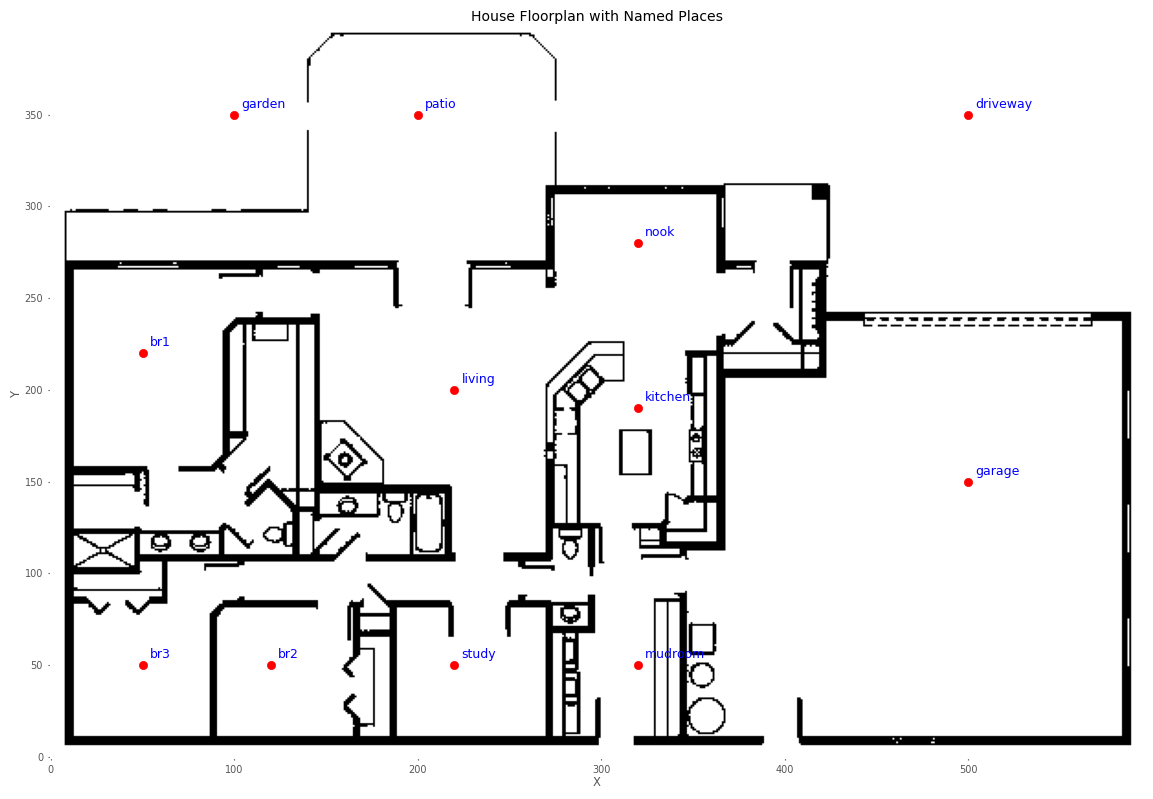

In [6]:
# Plot floorplan
fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(floorplan, cmap="gray_r", origin="lower")

# Plot and label all named places
for name in places.keys():
    position = np.asarray(places[name]).flatten()

    x, y = position[:2]

    ax.scatter(x, y, color="red", s=35, zorder=2)
    ax.annotate(
        name,
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        color="blue"
    )

ax.set_title("House Floorplan with Named Places")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")
ax.grid(False)

plt.tight_layout()
plt.show()

In [7]:
places.br3

array([50, 50], dtype=uint8)

In [8]:
bug = Bug2(occgrid=floorplan)

Bug2: 
  BinaryOccupancyGrid: 596 x 397, cell size=1, x = [0.0, 595.0], y = [0.0, 396.0], 8.8% occupied

<Axes: xlabel='x', ylabel='y'>

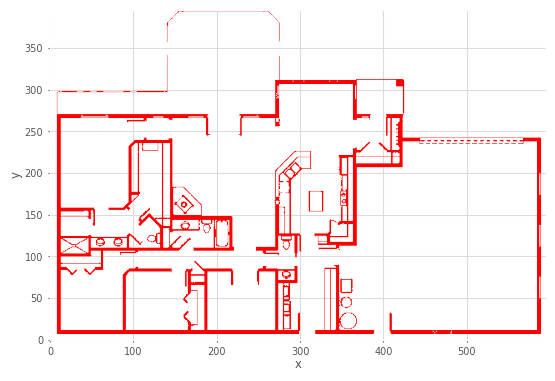

In [9]:
bug.plot()

array([[      50,       50],
       [      51,       51],
       [      52,       51],
       ...,
       [     318,      189],
       [     319,      189],
       [     320,      190]], shape=(1307, 2))

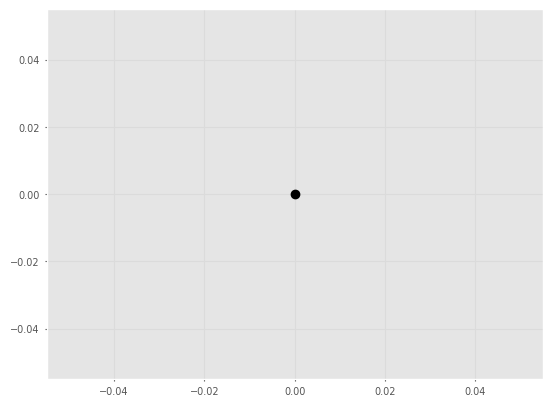

In [12]:
bug.run(
    start=places.br3,
    goal=places.kitchen,
    animate=False
)

In [13]:
places.br3

array([50, 50], dtype=uint8)

(1307, 2)

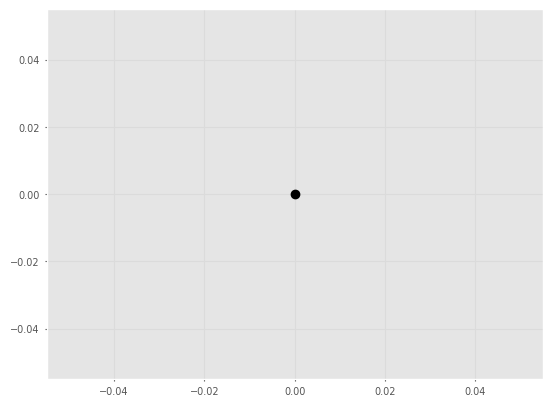

In [13]:
path = bug.run(start=places.br3, goal=places.kitchen)
path.shape